# Open-Meteo NCR data exploration

Exploration of the three files in `datasets/`:

| File | What it is |
|---|---|
| `ncr_weather_daily_2020-2026.csv` | Daily weather and river discharge per location |
| `ncr_flood_features_daily.csv` | The same days with rolling rain totals and discharge features added |
| `ncr_locations.csv` | The 17 sampled points: city, coordinates, elevation |

Questions: Is the data complete and consistent? How is rain distributed over time and by city? Which features move together? What should be fixed before modelling?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets").is_dir())  # repo root, wherever the notebook lives
DATA = REPO / "datasets"

# Chart style: one blue for magnitude, thin marks, quiet grid, no top/right frame.
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GRID = "#d9d8d4"
plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "lines.linewidth": 1.5, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

weather = pd.read_csv(DATA / "ncr_weather_daily_2020-2026.csv", parse_dates=["date"])
features = pd.read_csv(DATA / "ncr_flood_features_daily.csv", parse_dates=["date"])
locations = pd.read_csv(DATA / "ncr_locations.csv", encoding="utf-8-sig")  # file starts with a BOM

# Add the city to each daily row so results can be grouped by city.
city_of = locations.set_index("location_id")["city"]
weather["city"] = weather["location_id"].map(city_of)
features["city"] = features["location_id"].map(city_of)

print("weather :", weather.shape)
print("features:", features.shape)
print("locations:", locations.shape)

weather : (42313, 12)
features: (42313, 18)
locations: (17, 6)


## 1. Structure and completeness

In [2]:
def describe_table(df, name):
    """One row per file: size, date range, locations, duplicate rows."""
    return {
        "file": name, "rows": len(df), "columns": df.shape[1],
        "first_day": df["date"].min().date(), "last_day": df["date"].max().date(),
        "locations": df["location_id"].nunique(),
        "duplicate_location_days": int(df.duplicated(["location_id", "date"]).sum()),
    }


pd.DataFrame([describe_table(weather, "weather"), describe_table(features, "features")])

,file,rows,columns,first_day,last_day,locations,duplicate_location_days
0,weather,42313,12,2020-01-01,2026-10-24,17,0
1,features,42313,18,2020-01-01,2026-10-24,17,0


In [3]:
# Every location should have one row for every day in the range.
expected_days = (weather["date"].max() - weather["date"].min()).days + 1
days_per_location = weather.groupby("location_id").size()
print("expected days per location:", expected_days)
print("days per location (unique counts):", days_per_location.unique())
print("same location/day keys in both files:",
      set(zip(weather.location_id, weather.date)) == set(zip(features.location_id, features.date)))

expected days per location: 2489
days per location (unique counts): [2489]


same location/day keys in both files: True


## 2. Missing values

In [4]:
missing = pd.DataFrame({
    "weather_%": (weather.isna().mean() * 100).round(1),
    "features_%": (features.isna().mean() * 100).round(1),
})
missing[(missing > 0).any(axis=1)]

,weather_%,features_%
discharge_change_1d_pct,NaN,2.8
temperature_2m_max_c,18.0,NaN
temperature_2m_min_c,18.0,NaN


In [5]:
# Where are the temperature gaps? By year and by location.
temperature_missing = weather["temperature_2m_max_c"].isna()
by_year = temperature_missing.groupby(weather["date"].dt.year).mean().mul(100).round(1)
by_location = temperature_missing.groupby(weather["location_id"]).mean().mul(100).round(1)
print("Missing temperature_2m_max_c, % by year:\n", by_year.to_string())
print("\nBy location (min / max %):", by_location.min(), "/", by_location.max())

# The *_from_hourly columns are complete, so they can fill the gaps.
both = weather.dropna(subset=["temperature_2m_max_c"])
difference = (both["temperature_2m_max_c"] - both["temperature_2m_max_from_hourly_c"])
print("\nDaily max vs max-from-hourly, difference in C:")
print(difference.describe().round(2).to_string())

Missing temperature_2m_max_c, % by year:
 date
2020    100.0
2021     22.2
2022      0.0
2023      0.0
2024      0.0
2025      0.0
2026      0.0

By location (min / max %): 18.0 / 18.0

Daily max vs max-from-hourly, difference in C:
count    34714.00
mean         0.54
std          1.21
min         -4.60
25%          0.00
50%          0.30
75%          1.30
max          5.60


## 3. Locations

In [6]:
locations_summary = locations.groupby("city").agg(
    points=("location_id", "count"),
    distinct_coordinates=("coord_group", "nunique"),
    min_elevation_m=("elevation_m", "min"),
    max_elevation_m=("elevation_m", "max"),
)
display(locations_summary)
print("17 location ids but only", locations["coord_group"].nunique(), "distinct coordinates (coord_group)")

,points,distinct_coordinates,min_elevation_m,max_elevation_m
city,,,,
Las Piñas,3,1,18.0,24.0
Manila,5,1,9.0,29.0
Marikina,1,1,15.0,15.0
Pasig,1,1,8.0,8.0
Quezon City,2,1,7.0,48.0
Taguig,2,1,7.0,15.0
Valenzuela,3,1,4.0,9.0


17 location ids but only 7 distinct coordinates (coord_group)


In [7]:
# Points that share coordinates also share a weather grid cell. Does the weather differ between them?
rain = weather.pivot(index="date", columns="location_id", values="precipitation_sum_mm")
for group, ids in locations.groupby("coord_group")["location_id"].apply(list).items():
    if len(ids) > 1:
        identical = all(rain[ids[0]].equals(rain[other]) for other in ids[1:])
        elevations = locations.set_index("location_id").loc[ids, "elevation_m"].tolist()
        print(f"coord_group {group} ids {ids}: identical rain = {identical}, elevations {elevations}")

coord_group 0 ids [1, 7, 9]: identical rain = True, elevations [18.0, 24.0, 18.0]
coord_group 1 ids [12, 15]: identical rain = True, elevations [7.0, 15.0]
coord_group 2 ids [2, 4, 5, 10, 14]: identical rain = True, elevations [9.0, 15.0, 9.0, 15.0, 29.0]
coord_group 4 ids [0, 13]: identical rain = True, elevations [7.0, 48.0]
coord_group 6 ids [3, 8, 16]: identical rain = True, elevations [4.0, 5.0, 9.0]


## 4. Distributions

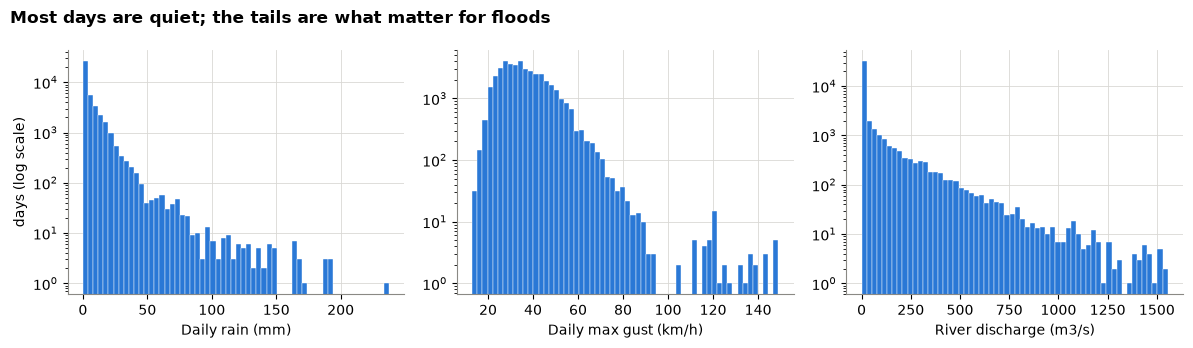

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for axis, column, label in [
    (axes[0], "precipitation_sum_mm", "Daily rain (mm)"),
    (axes[1], "wind_gusts_10m_max_kmh", "Daily max gust (km/h)"),
    (axes[2], "river_discharge_m3s", "River discharge (m3/s)"),
]:
    axis.hist(weather[column], bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
    axis.set_yscale("log")  # most days are small, so a log count axis keeps the tail visible
    axis.set_xlabel(label)
axes[0].set_ylabel("days (log scale)")
fig.suptitle("Most days are quiet; the tails are what matter for floods", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()

In [9]:
rain_days = weather["precipitation_sum_mm"]
print("Share of days with any rain (>0 mm):", round((rain_days > 0).mean() * 100, 1), "%")
print("Share of days >= 10 mm  :", round((rain_days >= 10).mean() * 100, 1), "%")
print("Share of days >= 50 mm  :", round((rain_days >= 50).mean() * 100, 2), "%")
print("Share of days >= 100 mm :", round((rain_days >= 100).mean() * 100, 3), "%")
weather[["precipitation_sum_mm", "wind_speed_10m_max_kmh", "wind_gusts_10m_max_kmh",
         "river_discharge_m3s"]].describe(percentiles=[0.5, 0.9, 0.99]).round(2)

Share of days with any rain (>0 mm): 85.0 %
Share of days >= 10 mm  : 19.8 %
Share of days >= 50 mm  : 1.07 %
Share of days >= 100 mm : 0.196 %


,precipitation_sum_mm,wind_speed_10m_max_kmh,wind_gusts_10m_max_kmh,river_discharge_m3s
count,42313.00,42313.00,42313.00,42313.00
mean,6.18,15.91,36.63,50.52
std,11.33,6.18,11.25,131.26
min,0.00,3.50,13.00,0.00
50%,2.00,14.90,34.90,2.94
90%,16.90,24.00,51.10,159.69
99%,53.16,33.40,69.10,661.04
max,237.50,77.40,149.00,1554.97


## 5. Seasonality and trend
Rain should follow the Philippine wet season (roughly June to October).

{1: 66,
 2: 54,
 3: 35,
 4: 49,
 5: 155,
 6: 256,
 7: 383,
 8: 331,
 9: 337,
 10: 277,
 11: 162,
 12: 136}

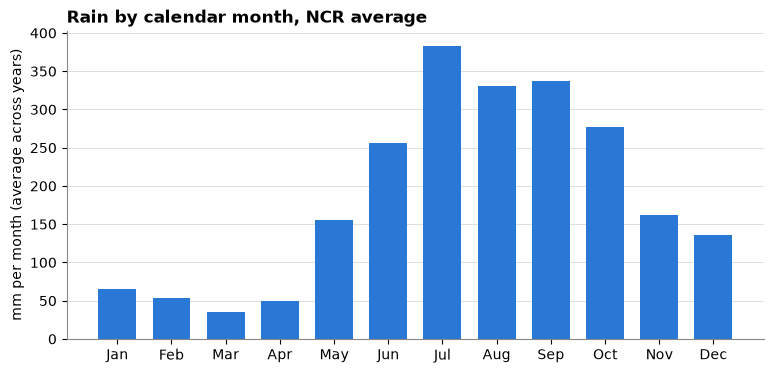

In [10]:
# Average over locations first, so every day counts once.
daily_mean = weather.groupby("date")["precipitation_sum_mm"].mean()
monthly_total = daily_mean.groupby([daily_mean.index.year, daily_mean.index.month]).sum()
monthly_total.index.names = ["year", "month"]
average_by_month = monthly_total.groupby("month").mean()

fig, axis = plt.subplots()
axis.bar(average_by_month.index, average_by_month.values, color=BLUE, width=0.7)
axis.set_xticks(range(1, 13))
axis.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
axis.set_ylabel("mm per month (average across years)")
axis.set_title("Rain by calendar month, NCR average")
axis.grid(axis="x", visible=False)
average_by_month.round(0).astype(int).to_dict()

In [11]:
# Is the last year complete? 2026 stops in October, so compare years on days that exist.
days_per_year = weather[weather.location_id == 0].groupby(weather["date"].dt.year).size()
yearly_total = daily_mean.groupby(daily_mean.index.year).sum()
summary = pd.DataFrame({"days_in_data": days_per_year, "total_rain_mm": yearly_total.round(0)})
summary["mm_per_day"] = (summary["total_rain_mm"] / summary["days_in_data"]).round(2)
summary

,days_in_data,total_rain_mm,mm_per_day
date,,,
2020,366,2363.0,6.46
2021,365,2037.0,5.58
2022,365,2473.0,6.78
2023,365,1983.0,5.43
2024,366,2314.0,6.32
2025,365,2467.0,6.76
2026,297,1754.0,5.91


## 6. By city

In [12]:
by_city = features.groupby("city").agg(
    mean_daily_rain_mm=("precipitation_sum_mm", "mean"),
    heavy_days_50mm=("precipitation_sum_mm", lambda s: int((s >= 50).sum())),
    max_rain_14d_mm=("rain_14d_mm", "max"),
    mean_discharge_m3s=("river_discharge_m3s", "mean"),
    max_discharge_m3s=("river_discharge_m3s", "max"),
).round(2).sort_values("mean_discharge_m3s", ascending=False)
by_city

,mean_daily_rain_mm,heavy_days_50mm,max_rain_14d_mm,mean_discharge_m3s,max_discharge_m3s
city,,,,,
Taguig,5.98,50,371.6,148.22,1509.08
Manila,6.26,140,387.7,99.26,1554.97
Pasig,6.36,27,361.1,36.30,457.14
Valenzuela,6.04,84,408.8,5.43,108.40
Quezon City,6.60,50,382.5,4.01,88.54
Marikina,7.93,36,471.0,1.70,24.70
Las Piñas,5.42,66,359.1,1.25,49.93


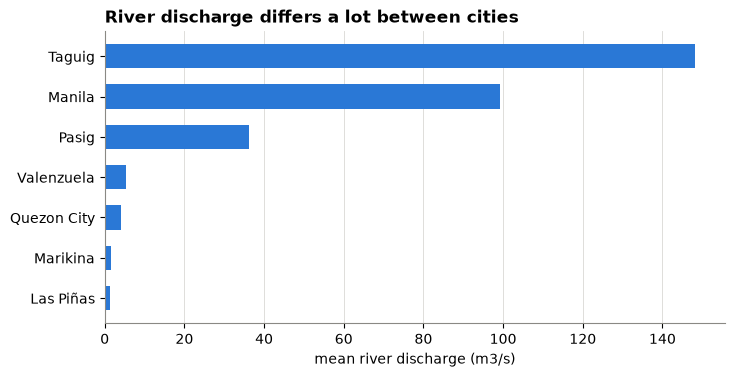

In [13]:
ordered = by_city["mean_discharge_m3s"].sort_values()
fig, axis = plt.subplots(figsize=(8, 3.8))
axis.barh(ordered.index, ordered.values, color=BLUE, height=0.6)
axis.set_xlabel("mean river discharge (m3/s)")
axis.set_title("River discharge differs a lot between cities")
axis.grid(axis="y", visible=False)

## 7. Extreme days

In [14]:
top_days = (
    features.nlargest(10, "precipitation_sum_mm")
    [["date", "city", "location_id", "precipitation_sum_mm", "rain_max_1h_mm", "rain_3d_mm", "river_discharge_m3s"]]
)
top_days

,date,city,location_id,precipitation_sum_mm,rain_max_1h_mm,rain_3d_mm,river_discharge_m3s
15249,2020-11-11,Marikina,6,237.5,42.0,295.3,21.28
27694,2020-11-11,Pasig,11,191.1,33.2,206.7,447.75
315,2020-11-11,Quezon City,0,190.9,35.4,204.9,88.54
32672,2020-11-11,Quezon City,13,190.9,35.4,204.9,45.99
7782,2020-11-11,Valenzuela,3,186.8,37.8,192.2,88.54
20227,2020-11-11,Valenzuela,8,186.8,37.8,192.2,108.40
40139,2020-11-11,Valenzuela,16,186.8,37.8,192.2,83.72
15227,2020-10-20,Marikina,6,173.7,19.4,187.8,10.83
3521,2022-10-29,Las Piñas,1,167.9,20.2,208.6,6.85
18455,2022-10-29,Las Piñas,7,167.9,20.2,208.6,7.34


Distinct calendar days with >= 50 mm at any location, by year:
date
2020    11
2021     7
2022     6
2023     2
2024    11
2025     5
2026     3


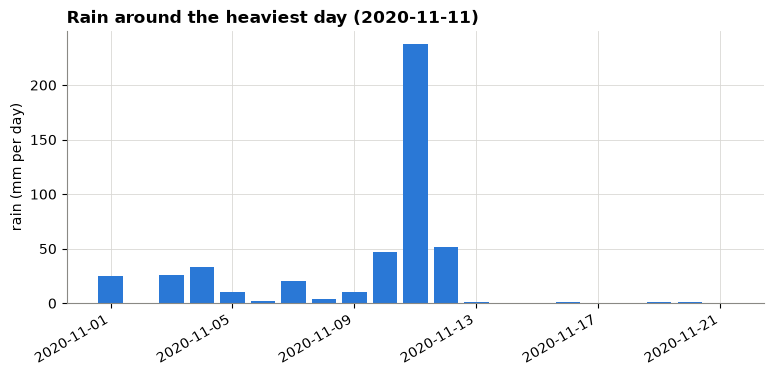

In [15]:
heavy = features[features["precipitation_sum_mm"] >= 50]
heavy_per_year = heavy.groupby(heavy["date"].dt.year)["date"].nunique()
print("Distinct calendar days with >= 50 mm at any location, by year:")
print(heavy_per_year.to_string())

# A heavy-rain period is a good test of whether the lag features line up.
worst_day = features.loc[features["precipitation_sum_mm"].idxmax(), "date"]
window = features[(features.location_id == features.loc[features["precipitation_sum_mm"].idxmax(), "location_id"])
                  & features["date"].between(worst_day - pd.Timedelta(days=10), worst_day + pd.Timedelta(days=10))]
fig, axis = plt.subplots()
axis.bar(window["date"], window["precipitation_sum_mm"], color=BLUE, width=0.8)
axis.set_ylabel("rain (mm per day)")
axis.set_title(f"Rain around the heaviest day ({worst_day.date()})")
fig.autofmt_xdate()

## 8. Checking the derived features
The features file adds rolling totals. Confirm they match the raw rain before trusting them.

In [16]:
def rolling_sum_check(window_days):
    """Largest difference between a stored rain_Nd_mm and a trailing N-day sum recomputed per location."""
    recomputed = features.groupby("location_id")["precipitation_sum_mm"].transform(
        lambda s: s.rolling(window_days, min_periods=1).sum()
    )
    return float((features[f"rain_{window_days}d_mm"] - recomputed).abs().max())


for days in (3, 7, 14):
    print(f"rain_{days}d_mm vs recomputed trailing sum, max abs difference: {rolling_sum_check(days):.3f}")

same_raw = ["precipitation_sum_mm", "wind_speed_10m_max_kmh", "wind_gusts_10m_max_kmh", "river_discharge_m3s"]
merged = weather.merge(features, on=["location_id", "date"], suffixes=("_w", "_f"))
for column in same_raw:
    print(f"{column}: identical in both files = {merged[column + '_w'].equals(merged[column + '_f'])}")

rain_3d_mm vs recomputed trailing sum, max abs difference: 0.000
rain_7d_mm vs recomputed trailing sum, max abs difference: 0.000
rain_14d_mm vs recomputed trailing sum, max abs difference: 0.000
precipitation_sum_mm: identical in both files = True
wind_speed_10m_max_kmh: identical in both files = True
wind_gusts_10m_max_kmh: identical in both files = True
river_discharge_m3s: identical in both files = True


In [17]:
# discharge_change_1d_pct divides by yesterday's discharge, so tiny values blow it up.
change = features["discharge_change_1d_pct"].dropna()
print(change.describe(percentiles=[0.01, 0.5, 0.99]).round(1).to_string())
print("\nRows with change > 1000 %:", int((change > 1000).sum()))
extreme = features.loc[features["discharge_change_1d_pct"].nlargest(3).index,
                       ["location_id", "date", "river_discharge_m3s", "discharge_change_1d_pct"]]
extreme

count    41132.0
mean        34.8
std        796.9
min       -100.0
1%         -61.0
50%         -2.7
99%        535.3
max      88450.0

Rows with change > 1000 %: 228


,location_id,date,river_discharge_m3s,discharge_change_1d_pct
17760,7,2020-12-03,17.71,88450.0
18477,7,2022-11-20,11.74,58600.0
17585,7,2020-06-11,15.18,50500.0


## 9. Which features move together

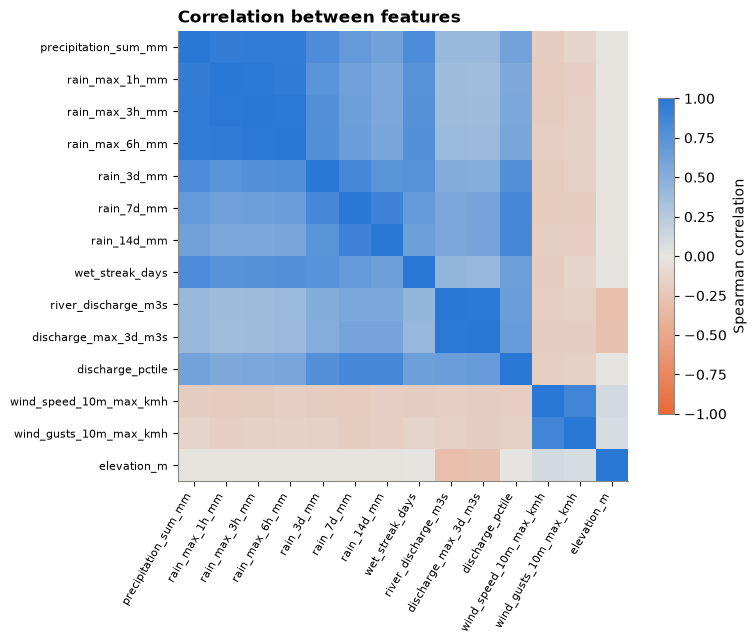

In [18]:
from matplotlib.colors import LinearSegmentedColormap

feature_columns = [
    "precipitation_sum_mm", "rain_max_1h_mm", "rain_max_3h_mm", "rain_max_6h_mm",
    "rain_3d_mm", "rain_7d_mm", "rain_14d_mm", "wet_streak_days",
    "river_discharge_m3s", "discharge_max_3d_m3s", "discharge_pctile",
    "wind_speed_10m_max_kmh", "wind_gusts_10m_max_kmh", "elevation_m",
]
correlation = features[feature_columns].corr(method="spearman")  # rank-based, so outliers matter less

# Two hues with a neutral middle: negative = orange, zero = grey, positive = blue.
diverging = LinearSegmentedColormap.from_list("div", [ORANGE, "#e6e5e1", BLUE])
fig, axis = plt.subplots(figsize=(8, 6.5))
image = axis.imshow(correlation, cmap=diverging, vmin=-1, vmax=1)
axis.set_xticks(range(len(feature_columns)), feature_columns, rotation=60, ha="right", fontsize=8)
axis.set_yticks(range(len(feature_columns)), feature_columns, fontsize=8)
axis.grid(False)
fig.colorbar(image, shrink=0.7, label="Spearman correlation")
axis.set_title("Correlation between features")
fig.tight_layout()

In [19]:
# The strongest pairs (each pair once), to read the heatmap in words.
pairs = correlation.where(np.triu(np.ones(correlation.shape, dtype=bool), k=1)).stack()
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(2)

rain_max_3h_mm        rain_max_6h_mm          0.99
river_discharge_m3s   discharge_max_3d_m3s    0.99
rain_max_1h_mm        rain_max_3h_mm          0.98
                      rain_max_6h_mm          0.97
precipitation_sum_mm  rain_max_6h_mm          0.96
                      rain_max_3h_mm          0.96
                      rain_max_1h_mm          0.94
rain_7d_mm            rain_14d_mm             0.89
dtype: float64

## 10. Does rain lead discharge?
For flood prediction, discharge should react to rain with a delay. A lag check for one location:

{0: np.float64(0.18),
 1: np.float64(0.25),
 2: np.float64(0.11),
 3: np.float64(-0.12),
 4: np.float64(-0.14),
 5: np.float64(-0.14),
 6: np.float64(-0.13),
 7: np.float64(-0.08)}

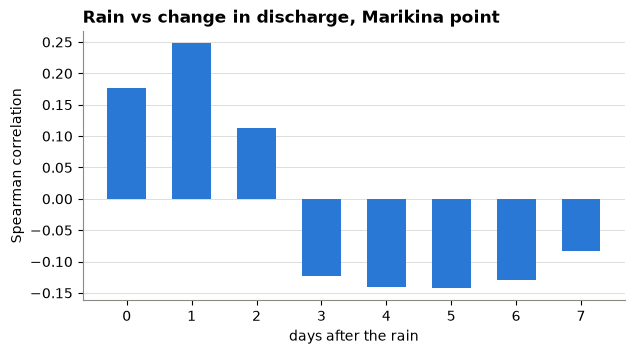

In [20]:
one_location = features[features.location_id == 6].set_index("date")  # Marikina
lags = range(0, 8)
lag_correlation = [
    one_location["precipitation_sum_mm"].corr(one_location["discharge_change_1d_pct"].clip(-100, 500).shift(-lag), method="spearman")
    for lag in lags
]
fig, axis = plt.subplots(figsize=(7, 3.5))
axis.bar(list(lags), lag_correlation, color=BLUE, width=0.6)
axis.set_xlabel("days after the rain")
axis.set_ylabel("Spearman correlation")
axis.set_title("Rain vs change in discharge, Marikina point")
axis.grid(axis="x", visible=False)
dict(zip(lags, np.round(lag_correlation, 2)))

## Findings

**Structure**
- Both daily files cover 2020-01-01 to 2026-10-24 for 17 locations (2,489 days each, 42,313 rows), with no duplicate location-days and no missing days. They share the same keys, and the raw columns match exactly.
- The features file adds 11 columns. The rolling rain totals (`rain_3d_mm`, `rain_7d_mm`, `rain_14d_mm`) match a recomputed trailing sum exactly.
- There is **no flood label** in any file, so supervised flood prediction needs a label from another source (or a rain / discharge threshold as a proxy).

**Gaps and quirks**
- `temperature_2m_max_c` and `temperature_2m_min_c` are missing for all of 2020 and about 22% of 2021 (18% overall). The `*_from_hourly_c` columns are complete, but the hourly-derived daily max is on average 0.5 C lower than the daily-max column (differences range from -4.6 to +5.6 C), so they are a rough substitute, not an exact one.
- `discharge_change_1d_pct` is empty on 2.8% of rows (17 are each location's first day; the other 1,164 follow a day with zero discharge) and has extreme values (max 88,450%, 228 rows above 1,000%) because it divides by a tiny previous-day discharge. Clip it or use `discharge_pctile` instead.
- The 17 locations sit on only 7 distinct coordinates. Locations sharing coordinates have **identical rain** and differ only in elevation (and discharge). Treat them as one weather grid cell when splitting train and test data, or the same rain will leak between sets.

**Weather behaviour**
- It rains on 85% of days, but only 1.07% of location-days reach 50 mm and 0.2% reach 100 mm. Rain, gusts and discharge are all heavily right-skewed.
- Rain follows the wet season: July (383 mm) to September (337 mm) are the wettest months on average, February to April the driest (35 to 54 mm).
- The heaviest day in the data is 2020-11-11 (237.5 mm at the Marikina point, with 186 to 191 mm at Pasig, Quezon City and Valenzuela).
- Yearly rain is steady (about 5.4 to 6.8 mm per day); 2026 is partial.

**Relationships**
- Short-window rain features (1 h, 3 h, 6 h and the daily total) are strongly correlated (0.94 to 0.99), so they carry similar information. `discharge_max_3d_m3s` is almost the same as `river_discharge_m3s` (0.99).
- Elevation is only weakly related to the other features in this view.
- In the Marikina lag check, rain is mildly correlated with the next one to two days of discharge change (0.18 to 0.25) and not after that. This is one location with a crude statistic, so treat it as a hint only.

**Before modelling**
1. Choose or build a flood label.
2. Fill or drop the 2020-2021 temperature gaps.
3. Clip or drop `discharge_change_1d_pct`.
4. Split by time and by coordinate group, not by random row.
5. Drop one of each near-duplicate feature pair (for example `rain_max_3h_mm` / `rain_max_6h_mm`).